# 01 — Meet the dataset

**Question:** What did we record, and what does one row mean?

**By the end:** you can connect a market to its two instruments, distinguish a
snapshot from an update or trade, identify units, and trace a normalized record
back to its raw evidence. No pandas experience is assumed: read the explanation,
run the next cell, then look at its output.

**Time:** 25–35 minutes. **Inputs:** the checksum-pinned teaching sample.

Our common example is one actual BTC five-minute market. Earlier book history is
retained to reconstruct its opening state. Later resolution observations are
retrospective labels. This extract is not a full raw-archive verification or proof
of trading profitability. Unsupported semantics stay unsupported.

In [1]:
import sys
from pathlib import Path

# Works when Jupyter starts at the repository root or in the notebook folder.
for directory in (Path.cwd(), *Path.cwd().parents):
    if (directory / "src/tyrex_pm").exists():
        sys.path.insert(0, str(directory / "src"))
        break

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from tyrex_pm.research.tuto_btc5m.analysis import (
    finish_plot,
    notebook_inventory,
    plot_style,
)
from tyrex_pm.research.tuto_btc5m.data import Sample

SAMPLE_PATH = None  # Or Path("/absolute/path/to/your/prepared_sample")
sample = Sample.open(SAMPLE_PATH)
plot_style()
pd.set_option("display.max_columns", 12)
display(pd.Series(sample.describe(), name="Pinned input"))

collection                             2dd3d0d125dc4a9fb5e50daf3f9bfd3e
market                polymarket:condition:0x540c56b66edcf6f1273c7d7...
start_utc                                     2026-10-01 15:45:00+00:00
end_utc                                       2026-10-01 15:50:00+00:00
manifest_sha256       f5a2aa939c7d60a1f48d1f6df5c0110a61dc11a7794458...
integrity_scope       selected_normalized_parts_and_sample_only_not_...
semantic_readiness                                          UNSUPPORTED
Name: Pinned input, dtype: object

## 1. A map before the numbers

Think of the collection as a recording project and a session as one recorder run.
A **market** is the question for one five-minute window. An **instrument** is an
outcome token inside it. A **feed** is a stream measuring a particular thing.

```
Collection → Sessions → Raw messages → Normalized observations
                         Market → Up token / Down token
                         Feed → BTC trades / reference observations
                         Quality → retrospective coverage and boundary reports
```

Several normalized rows can come from one raw message. A raw ID is therefore a
lineage link, not a guarantee that every row is an independent observation.

In [2]:
inventory = notebook_inventory(sample)
display(inventory.round({"size_KiB": 1}))
market = sample.frame("markets").drop_duplicates("market_id", keep="last")
instruments = sample.frame("instruments").drop_duplicates("instrument_id", keep="last")
display(market[["market_id", "underlying_asset", "duration_s"]])
display(instruments[["venue_label", "outcome_index", "price_unit", "quantity_unit"]])

,dataset,rows,size_KiB
0,markets,38,12.6
1,instruments,76,16.5
2,metadata_versions,48,34.9
3,feeds,2,10.9
4,feed_bindings,2,11.3
5,book_snapshots,1964,631.0
6,book_updates,153652,15070.6
7,quote_observations,2310,134.2
8,trade_prints,26856,1346.6
9,reference_observations,1385,109.6


,market_id,underlying_asset,duration_s
37,polymarket:condition:0x540c56b66edcf6f1273c7d7...,BTC,300


,venue_label,outcome_index,price_unit,quantity_unit
74,Up,0,USD_per_share,shares
75,Down,1,USD_per_share,shares


## 2. What dominates the recording?

The next chart counts **normalized sample rows**, not unique trades or independent
windows. It includes the earlier reconstruction history. A busy update channel
can dominate storage even though the market still asks only one eventual question.

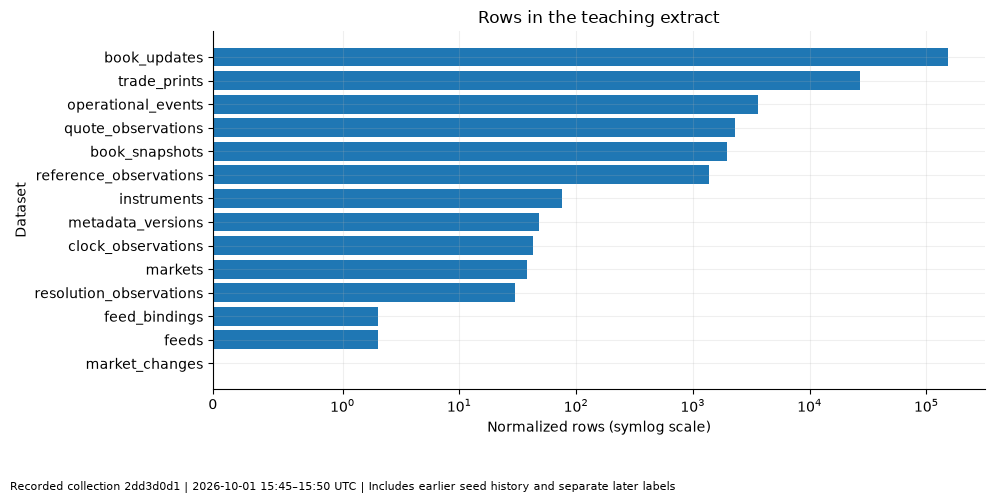

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
counts = inventory.set_index("dataset").rows.sort_values()
ax.barh(counts.index, counts.values)
ax.set_xscale("symlog", linthresh=1)
ax.set(
    title="Rows in the teaching extract", xlabel="Normalized rows (symlog scale)", ylabel="Dataset"
)
finish_plot(fig, sample, "Includes earlier seed history and separate later labels")

## 3. Snapshot, update, quote, trade: four different observations

- **Snapshot:** displayed quantities at a set of price levels at one instant.
- **Update:** a price level now has a new quantity. Rebuild it from a prior seed;
  the new quantity is an absolute level quantity, not an amount to add blindly.
- **Quote:** a reported best bid and ask; it does not reveal the full depth.
- **Trade:** an execution reported by the provider; it is not a standing order.

A fall from 100 to 70 displayed shares means 30 shares disappeared from that
level. This public data alone does not tell us that all 30 were cancellations.

In [4]:
snapshot = next(r for r in sample.records("book_snapshots") if r["snapshot_origin"] != "rest_audit")
update = sample.records("book_updates")[0]
display(pd.DataFrame(snapshot["bids"][:3]))
display(pd.DataFrame(update["changes"][:3])[["instrument_id", "side", "price", "new_quantity"]])
trades = sample.frame("trade_prints")
display(trades.groupby("source_id").size().rename("Recorded trade rows"))
display(trades[["source_id", "trade_kind", "price", "quantity", "reported_side"]].head())

,price,quantity
0,0.500000000000000000000000000000,80.660000000000000000000000000000
1,0.490000000000000000000000000000,501.230000000000000000000000000000
2,0.480000000000000000000000000000,291.410000000000000000000000000000


,instrument_id,side,price,new_quantity
0,polymarket:137:outcome:51567368491506077303718...,BUY,0.010000000000000000000000000000,101670.750000000000000000000000000000
1,polymarket:137:outcome:51821137619308110358810...,SELL,0.990000000000000000000000000000,101670.750000000000000000000000000000


source_id
binance    25993
clob         863
Name: Recorded trade rows, dtype: int64

,source_id,trade_kind,price,quantity,reported_side
0,clob,public_print,0.650000000000000000000000000000,2.307691000000000000000000000000,BUY
1,clob,public_print,0.380000000000000000000000000000,60.000000000000000000000000000000,BUY
2,clob,public_print,0.640000000000000000000000000000,5.312500000000000000000000000000,BUY
3,binance,individual,83889.440000000000000000000000000000,0.000090000000000000000000000000,NaN
4,clob,public_print,0.630000000000000000000000000000,1.587302000000000000000000000000,BUY


## 4. Provenance and exact numbers

`record_id` identifies the normalized row. `raw_record_id` and `payload_path`
identify its parent message and location inside that message. `session_id`,
`connection_id`, and `ingest_sequence` help establish the recorder's history.

Prices and sizes remain Decimal objects. We only convert to floats in separate
plotting/statistical views. Source prices are not rewritten for convenience.

In [5]:
display(
    pd.Series(
        {
            k: snapshot[k]
            for k in (
                "record_id",
                "raw_record_id",
                "payload_path",
                "session_id",
                "connection_id",
                "ingest_sequence",
                "source_time_precision",
                "snapshot_origin",
                "depth_scope",
            )
        }
    )
)
print("Price type:", type(snapshot["bids"][0]["price"]).__name__)
print("Price stored exactly:", snapshot["bids"][0]["price"])
print("Sample checksum:", sample.manifest_sha256)

record_id                739cfa9f997860990f2cd55d44939da782aec7f61db36f...
raw_record_id                       123c375b03284be3b395ef6117fd5504:21946
payload_path                                                          $[1]
session_id                                123c375b03284be3b395ef6117fd5504
connection_id                             912ac43848be489fad729f9b6ee4c134
ingest_sequence                                                      21946
source_time_precision                                                   ms
snapshot_origin                                                  websocket
depth_scope                                           published_aggregated
dtype: object

Price type: Decimal
Price stored exactly: 0.500000000000000000000000000000
Sample checksum: f5a2aa939c7d60a1f48d1f6df5c0110a61dc11a779445826900ffba6e928dbcc


## 5. Know which feed measures what

Before comparing two prices, inspect the instrument, currency, measurement type
and aggregation. A BTC/USDT trade and a BTC/USD TWAP are different observations.
The reference feed does not become an official opening threshold merely because
it is recorded. The recorded feed descriptors are evidence, not a substitute for
attested market rules.

In [6]:
feeds = sample.frame("feeds").drop_duplicates(["feed_id", "feed_version"])
display(
    feeds[
        [
            "feed_id",
            "provider",
            "measurement_type",
            "price_currency",
            "aggregation_window_s",
            "depth_scope",
        ]
    ]
)
bindings = sample.frame("feed_bindings").drop_duplicates("binding_id")
display(bindings[["feed_id", "role", "required"]])

,feed_id,provider,measurement_type,price_currency,aggregation_window_s,depth_scope
0,chainlink:btcusd:twap:60,chainlink,TWAP,USD,None,None
1,binance:spot:BTCUSDT,binance,trades_and_depth,USDT,None,None


,feed_id,role,required
0,chainlink:btcusd:twap:60,settlement_reference,True
1,binance:spot:BTCUSDT,explanatory_input,True


## Exercise — explain a row to someone else

Choose the first book update. Identify its parent raw message, the affected token,
its clock, and the unit of the new quantity. Does it identify a buyer?

**Suggested answer:** `raw_record_id` gives lineage; each nested change carries an
instrument ID. Local `received_at` is when our recorder knew it. Quantities are in
shares according to the recorded instrument descriptor. The public level update
does not identify a buyer, individual order, or our queue position.

**Research use:** join keys, provenance and units are the foundation of every
feature. **What remains unknown:** the complete raw archive is not verified by
this teaching extract, and many rows do not mean many independent examples.

Next: [02 — Data quality and time](02_data_quality_and_time.ipynb).